<a href="https://colab.research.google.com/github/hayetmece/algorithms-performance-analysis/blob/main/algorithms_performance_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Algorithms Performance Analysis
## Comparative Analysis of Sorting and Searching Algorithms Using Python

**Project objective:** compare sorting and searching algorithms using operation counts and execution time, then visualize how performance changes as input size grows.

### Algorithms included
- Sorting: Bubble Sort, Selection Sort, Insertion Sort, Merge Sort, Python's built-in `sorted()`
- Searching: Linear Search, Binary Search

### Important notes
- Binary Search requires sorted input.
- Execution time can vary with computer load, so repeat measurements and compare averages.
- Operation counts are useful for explaining behavior; they are not the same as elapsed time.


## 1. Imports and experiment settings

In [1]:
import random
import time
import statistics
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)

SIZES = [100, 500, 1000, 2000]
REPEATS = 3


## 2. Sorting algorithms with operation counters

In [2]:
def bubble_sort(arr):
    a = arr.copy()
    comparisons = swaps = 0
    n = len(a)
    for i in range(n):
        swapped = False
        for j in range(0, n - i - 1):
            comparisons += 1
            if a[j] > a[j + 1]:
                a[j], a[j + 1] = a[j + 1], a[j]
                swaps += 1
                swapped = True
        if not swapped:
            break
    return a, comparisons, swaps


def selection_sort(arr):
    a = arr.copy()
    comparisons = swaps = 0
    n = len(a)
    for i in range(n - 1):
        min_idx = i
        for j in range(i + 1, n):
            comparisons += 1
            if a[j] < a[min_idx]:
                min_idx = j
        if min_idx != i:
            a[i], a[min_idx] = a[min_idx], a[i]
            swaps += 1
    return a, comparisons, swaps


def insertion_sort(arr):
    a = arr.copy()
    comparisons = shifts = 0
    for i in range(1, len(a)):
        key = a[i]
        j = i - 1
        while j >= 0:
            comparisons += 1
            if a[j] > key:
                a[j + 1] = a[j]
                shifts += 1
                j -= 1
            else:
                break
        a[j + 1] = key
    return a, comparisons, shifts


def merge_sort(arr):
    comparisons = [0]

    def merge(left, right):
        result = []
        i = j = 0
        while i < len(left) and j < len(right):
            comparisons[0] += 1
            if left[i] <= right[j]:
                result.append(left[i])
                i += 1
            else:
                result.append(right[j])
                j += 1
        result.extend(left[i:])
        result.extend(right[j:])
        return result

    def sort(a):
        if len(a) <= 1:
            return a
        mid = len(a) // 2
        return merge(sort(a[:mid]), sort(a[mid:]))

    result = sort(arr.copy())
    return result, comparisons[0], None


def builtin_sort(arr):
    start = time.perf_counter()
    result = sorted(arr)
    elapsed = time.perf_counter() - start
    return result, None, None, elapsed


## 3. Validate that the algorithms return the same result

In [3]:
test_data = [8, 3, 7, 1, 9, 2, 5]
expected = sorted(test_data)

for name, algorithm in [
    ("Bubble Sort", bubble_sort),
    ("Selection Sort", selection_sort),
    ("Insertion Sort", insertion_sort),
    ("Merge Sort", merge_sort),
]:
    result, comparisons, swaps_or_shifts = algorithm(test_data)
    assert result == expected, f"{name} failed!"
    print(f"{name}: {result} | comparisons={comparisons} | swaps/shifts={swaps_or_shifts}")

print("All sorting algorithm tests passed.")


Bubble Sort: [1, 2, 3, 5, 7, 8, 9] | comparisons=20 | swaps/shifts=12
Selection Sort: [1, 2, 3, 5, 7, 8, 9] | comparisons=21 | swaps/shifts=6
Insertion Sort: [1, 2, 3, 5, 7, 8, 9] | comparisons=16 | swaps/shifts=12
Merge Sort: [1, 2, 3, 5, 7, 8, 9] | comparisons=14 | swaps/shifts=None
All sorting algorithm tests passed.


## 4. Benchmark sorting algorithms

In [4]:
sorting_algorithms = {
    "Bubble Sort": bubble_sort,
    "Selection Sort": selection_sort,
    "Insertion Sort": insertion_sort,
    "Merge Sort": merge_sort,
}

sorting_rows = []

for n in SIZES:
    data = [random.randint(0, n * 10) for _ in range(n)]
    for name, algorithm in sorting_algorithms.items():
        times = []
        comparisons_list = []
        swaps_list = []

        for _ in range(REPEATS):
            start = time.perf_counter()
            result, comparisons, swaps = algorithm(data)
            times.append(time.perf_counter() - start)
            comparisons_list.append(comparisons)
            if swaps is not None:
                swaps_list.append(swaps)

        sorting_rows.append({
            "Algorithm": name,
            "Input Size": n,
            "Average Time (seconds)": statistics.mean(times),
            "Comparisons": round(statistics.mean(comparisons_list)),
            "Swaps/Shifts": round(statistics.mean(swaps_list)) if swaps_list else None,
        })

sorting_df = pd.DataFrame(sorting_rows)
sorting_df


,Algorithm,Input Size,Average Time (seconds),Comparisons,Swaps/Shifts
0,Bubble Sort,100,0.000602,4740,2298.0
1,Selection Sort,100,0.000378,4950,93.0
2,Insertion Sort,100,0.000333,2394,2298.0
3,Merge Sort,100,0.000202,549,NaN
4,Bubble Sort,500,0.017068,123669,62124.0
5,Selection Sort,500,0.009823,124750,493.0
6,Insertion Sort,500,0.010826,62615,62124.0
7,Merge Sort,500,0.001670,3837,NaN
8,Bubble Sort,1000,0.121883,497085,253273.0
9,Selection Sort,1000,0.072951,499500,994.0


## 5. Plot sorting execution time

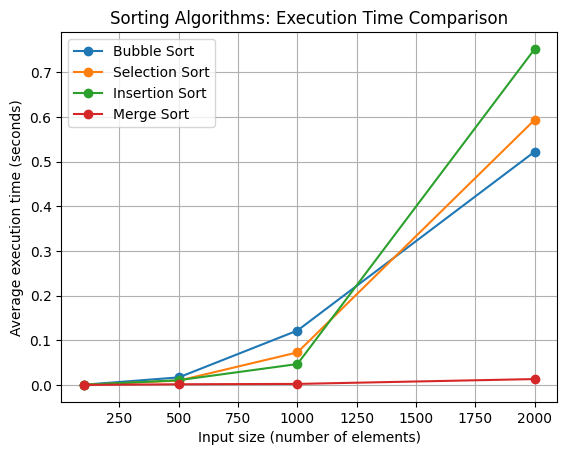

In [5]:
for name in sorting_algorithms:
    subset = sorting_df[sorting_df["Algorithm"] == name]
    plt.plot(subset["Input Size"], subset["Average Time (seconds)"], marker="o", label=name)

plt.xlabel("Input size (number of elements)")
plt.ylabel("Average execution time (seconds)")
plt.title("Sorting Algorithms: Execution Time Comparison")
plt.legend()
plt.grid(True)
plt.show()


## 6. Searching algorithms with operation counters

In [6]:
def linear_search(arr, target):
    comparisons = 0
    for index, value in enumerate(arr):
        comparisons += 1
        if value == target:
            return index, comparisons
    return -1, comparisons


def binary_search(arr, target):
    # The input array must already be sorted.
    left, right = 0, len(arr) - 1
    comparisons = 0

    while left <= right:
        mid = (left + right) // 2
        comparisons += 1

        if arr[mid] == target:
            return mid, comparisons
        elif arr[mid] < target:
            left = mid + 1
        else:
            right = mid - 1

    return -1, comparisons


## 7. Benchmark searching algorithms

In [7]:
search_rows = []

for n in SIZES:
    data = sorted(random.randint(0, n * 10) for _ in range(n))
    target = data[-1]  # Search for a value near the end to make linear search do more work.

    for name, algorithm in [("Linear Search", linear_search), ("Binary Search", binary_search)]:
        times = []
        comparisons_list = []

        for _ in range(REPEATS):
            start = time.perf_counter()
            index, comparisons = algorithm(data, target)
            times.append(time.perf_counter() - start)
            comparisons_list.append(comparisons)

        search_rows.append({
            "Algorithm": name,
            "Input Size": n,
            "Average Time (seconds)": statistics.mean(times),
            "Comparisons": round(statistics.mean(comparisons_list)),
            "Found Index": index,
        })

search_df = pd.DataFrame(search_rows)
search_df


,Algorithm,Input Size,Average Time (seconds),Comparisons,Found Index
0,Linear Search,100,0.000013,100,99
1,Binary Search,100,0.000004,7,99
2,Linear Search,500,0.000070,500,499
3,Binary Search,500,0.000005,9,499
4,Linear Search,1000,0.000147,1000,999
5,Binary Search,1000,0.000004,10,999
6,Linear Search,2000,0.000292,2000,1999
7,Binary Search,2000,0.000006,11,1999


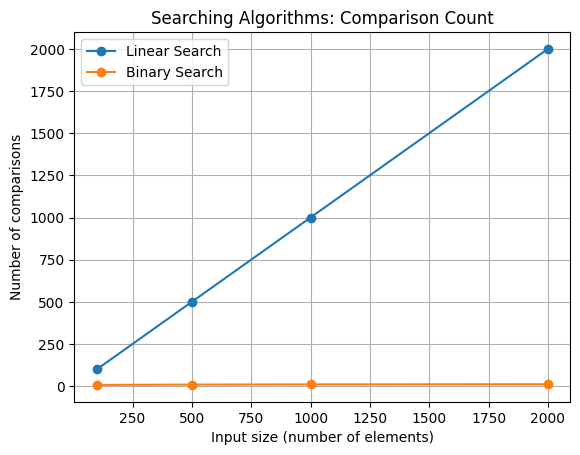

In [8]:
for name in ["Linear Search", "Binary Search"]:
    subset = search_df[search_df["Algorithm"] == name]
    plt.plot(subset["Input Size"], subset["Comparisons"], marker="o", label=name)

plt.xlabel("Input size (number of elements)")
plt.ylabel("Number of comparisons")
plt.title("Searching Algorithms: Comparison Count")
plt.legend()
plt.grid(True)
plt.show()


## 8. Complexity summary

| Algorithm | Best case | Average case | Worst case |
|---|---:|---:|---:|
| Bubble Sort (with early stopping) | O(n) | O(n²) | O(n²) |
| Selection Sort | O(n²) | O(n²) | O(n²) |
| Insertion Sort | O(n) | O(n²) | O(n²) |
| Merge Sort | O(n log n) | O(n log n) | O(n log n) |
| Linear Search | O(1) | O(n) | O(n) |
| Binary Search | O(1) | O(log n) | O(log n) |

## 9. Conclusions to investigate

After running the notebook, use your actual measurements to discuss:
1. Which sorting algorithm was fastest for each input size?
2. How did Merge Sort compare with the quadratic algorithms as input size increased?
3. How did the number of comparisons grow for Linear Search versus Binary Search?
4. Why can measured execution time differ between runs?
5. Why must Binary Search receive sorted data?

**Reproducibility:** the random seed is fixed, but execution times can still vary with the runtime environment.
